In [ ]:
import torch
import torch.nn as nn

from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split

import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

In [240]:
torch.manual_seed(1)

device = 'cuda' if torch.cuda.is_available() else 'cpu'
device

'cpu'

In [241]:
data = pd.read_csv('./data/processed/train.csv')

X = data.drop(columns=['Survived'])
y = data['Survived']

X['Embarked_Q'] = X['Embarked_Q'].astype(int)
X['Embarked_S'] = X['Embarked_S'].astype(int)

In [242]:
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.3, random_state=42)

In [243]:
X_train = torch.tensor(X_train.values, dtype=torch.float32, device=device)
X_val = torch.tensor(X_val.values, dtype=torch.float32, device=device)
y_train = torch.tensor(y_train.values, dtype=torch.long, device=device)
y_val = torch.tensor(y_val.values, dtype=torch.long, device=device)

In [244]:
train_dataset = TensorDataset(X_train, y_train)
val_dataset = TensorDataset(X_val, y_val)

In [245]:
train_loader = DataLoader(train_dataset, batch_size=16)
val_loader = DataLoader(val_dataset, batch_size=16)


In [246]:
class TitanicClassifier(nn.Module):
    def __init__(self, input, output):
        super().__init__()
        self.layer = nn.Linear(input, output)
        
    def forward(self, x):
        out = self.layer(x)
        
        return out

model = TitanicClassifier(10, 2)
model

TitanicClassifier(
  (layer): Linear(in_features=10, out_features=2, bias=True)
)

In [247]:
input = torch.rand([16, 10], dtype=torch.float32, device=device)

model(input).shape

torch.Size([16, 2])

In [248]:
loss_model = nn.CrossEntropyLoss()
opt = torch.optim.Adam(model.parameters(), lr=0.001)

In [249]:
EPOCHS = 50
train_loss = []
train_acc = []
val_loss = []
val_acc = []

for epoch in range(EPOCHS):
    model.train()
    running_train_loss = []
    true_answer = 0
    for x, targets in train_loader:
        pred = model(x)
        
        opt.zero_grad()
        
        loss = loss_model(pred, targets)
        loss.backward()
        opt.step()
        
        running_train_loss.append(loss.item())
        true_answer += (pred.argmax(dim=1) == targets).sum().item()
    
    train_loss.append(sum(running_train_loss) / len(running_train_loss))
    train_acc.append(true_answer / len(train_dataset))
    
    
    model.eval()
    with torch.no_grad():
        val_pred = model(X_val)
        
        loss = loss_model(val_pred, y_val)
    
        val_loss.append(loss.item())
        val_acc.append((val_pred.argmax(dim=1) == y_val).sum().item() / len(y_val))

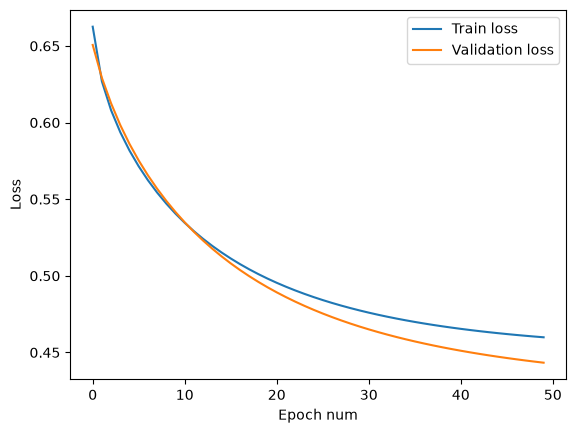

In [250]:
sns.lineplot(train_loss, label='Train loss')
sns.lineplot(val_loss, label='Validation loss')
plt.xlabel('Epoch num')
plt.ylabel('Loss');

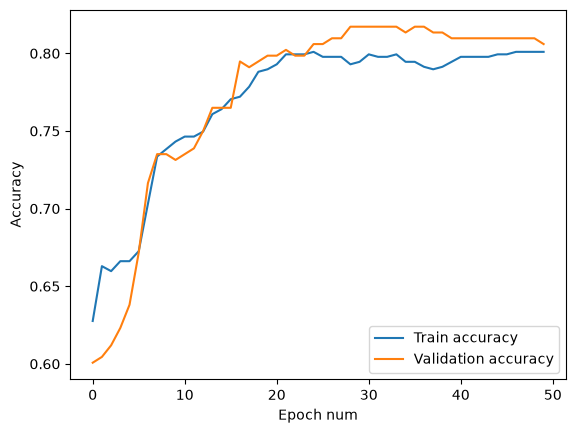

In [251]:
sns.lineplot(train_acc, label='Train accuracy')
sns.lineplot(val_acc, label='Validation accuracy')
plt.xlabel('Epoch num')
plt.ylabel('Accuracy');

In [253]:
print(train_acc[-1])
print(val_acc[-1])

0.8009630818619583
0.8059701492537313
